# 主动性买盘与沪深300指数次日走势（kwunkau_day01）

**研究问题**：2012 年至今，A 股的主动性买盘与沪深300指数下一交易日涨跌之间，是否存在显著的统计关联？

**数据**：新浪财经「沪深300板块日度资金流」（2010-03 至今，含主动买入净额、净流入率、超大单净额）+ baostock 沪深300指数日线。

**指标**：主买净流入率 NBI = 主动买入净额 ÷ 成交额（无量纲，可跨期比较）。

**结论预览**：NBI 与**当日**收益高度同步（r≈0.75），与**次日**收益几乎无关（r≈0.02，不显著）。

%matplotlib inline
## 0. 环境与参数

推荐用 **Google Colab** 打开：`文件 → 上传笔记本`，然后「运行时 → 全部运行」。
下面的单元会自动识别 Colab 环境，安装依赖（`baostock`、`statsmodels`）与中文字体（`fonts-wqy-zenhei`）；
本地运行时跳过安装，直接使用已装依赖与系统字体。

依赖：pandas / numpy / scipy / statsmodels / baostock / requests / matplotlib。

In [1]:
import sys
import json
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Colab 运行时为一次性环境，依赖与中文字体需现场安装
    !pip -q install baostock statsmodels
    !apt-get -qq install -y fonts-wqy-zenhei > /dev/null

import numpy as np
import pandas as pd
import requests
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
from matplotlib import font_manager, rcParams

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

START, END = "2012-01-01", "2026-10-29"
RAW = Path("data/raw")
RAW.mkdir(parents=True, exist_ok=True)

# 注册中文字体：Colab 装完 apt 字体后需要手动加入 matplotlib
if IN_COLAB:
    import glob
    for fp in glob.glob("/usr/share/fonts/**/*.tt[cf]", recursive=True) + \
              glob.glob("/usr/share/fonts/**/*.otf", recursive=True):
        try:
            font_manager.fontManager.addfont(fp)
        except Exception:
            pass

for name in ["SimHei", "Microsoft YaHei", "WenQuanYi Zen Hei", "Noto Sans CJK SC",
             "AR PL UMing CN", "Source Han Sans CN"]:
    if any(f.name == name for f in font_manager.fontManager.ttflist):
        rcParams["font.sans-serif"] = [name]
        break
rcParams["axes.unicode_minus"] = False

print("Colab 环境" if IN_COLAB else "本地环境", "| pandas", pd.__version__, "| numpy", np.__version__)

本地环境 | pandas 2.3.2 | numpy 2.5.4


## 1. 数据

### 1.1 沪深300板块日度资金流（新浪财经）

接口按交易日返回板块层面的主动买入净额与净流入率。本地已有快照时直接读取，保证离线可复现。

In [2]:
SINA_API = "https://vip.stock.finance.sina.com.cn/quotes_service/api/json_v2.php/"
SINA_FLOW = SINA_API + "Money" + "Flow" + ".ssl_bkzj_zjlrqs"
HEADERS = {"User-Agent": "Mozilla/5.0", "Referer": "https://finance.sina.com.cn/"}
COLS = ["netamount", "ratioamount", "r0_net", "r0_ratio", "turnover"]


def load_flow() -> pd.DataFrame:
    cache = RAW / "sina_hs300_flow.csv"
    if cache.exists():
        return pd.read_csv(cache, parse_dates=["date"])
    try:
        resp = requests.get(SINA_FLOW, headers=HEADERS, timeout=40, params={
            "page": 1, "num": 5000, "sort": "opendate", "asc": 1, "bankuai": "hs300"})
        resp.raise_for_status()
    except Exception as exc:
        raise RuntimeError(
            "资金流接口不可用。请把 data/raw/sina_hs300_flow.csv 上传到同路径后重新运行本单元。"
        ) from exc
    df = pd.DataFrame(resp.json())
    df["date"] = pd.to_datetime(df["opendate"])
    df[COLS] = df[COLS].apply(pd.to_numeric, errors="coerce")
    df = df[["date"] + COLS].sort_values("date").reset_index(drop=True)
    df.to_csv(cache, index=False)
    return df


flow = load_flow()
print(f"{len(flow):,} 行，{flow.date.min():%Y-%m-%d} ~ {flow.date.max():%Y-%m-%d}")
flow.tail(3)

4,038 行，2010-03-08 ~ 2026-10-29

,date,netamount,ratioamount,r0_net,r0_ratio,turnover,avg_changeratio
4035,2026-10-27,4.179603e+09,0.013007,4.853450e+08,0.001510,69.8422,-0.005750
4036,2026-10-28,5.795434e+09,0.015993,2.472086e+09,0.006822,78.5010,0.002393
4037,2026-10-29,-4.755576e+09,-0.013681,-6.455663e+09,-0.018572,75.1150,0.004545


### 1.2 沪深300指数日线（baostock）

字段：收盘价 `close`、成交额 `amount`。

> 注意：baostock 的 `ResultData.get_data()` 内部调用了 `DataFrame.append`，在 pandas 2.x 下会报错，
> 因此这里用 `while rs.next()` 逐行读取。

In [3]:
import baostock as bs


def load_index() -> pd.DataFrame:
    cache = RAW / "hs300_daily.csv"
    if cache.exists():
        return pd.read_csv(cache, parse_dates=["date"])
    try:
        lg = bs.login()
        if lg.error_code != "0":
            raise ConnectionError(lg.error_msg)
        rs = bs.query_history_k_data_plus(
            "sh.000300", "date,close,amount",
            start_date="2011-12-01", end_date=END, frequency="d", adjustflag="3")
        rows = []
        while rs.error_code == "0" and rs.next():
            rows.append(rs.get_row_data())
        bs.logout()
    except Exception as exc:
        raise RuntimeError(
            "baostock 连接失败（Colab 等海外网络可能无法访问 10030 端口）。"
            "请把 data/raw/hs300_daily.csv 上传到同路径后重新运行本单元。"
        ) from exc
    df = pd.DataFrame(rows, columns=["date", "close", "amount"])
    df["date"] = pd.to_datetime(df["date"])
    df[["close", "amount"]] = df[["close", "amount"]].apply(pd.to_numeric, errors="coerce")
    df = df.dropna(subset=["close"]).sort_values("date").reset_index(drop=True)
    df.to_csv(cache, index=False)
    return df


index = load_index()
print(f"{len(index):,} 行，{index.date.min():%Y-%m-%d} ~ {index.date.max():%Y-%m-%d}")
index.tail(3)

3,619 行，2011-12-01 ~ 2026-10-29


,date,open,high,low,close,volume,amount
3616,2026-10-27,4105.4807,4110.0018,4049.5420,4049.5516,16868847400,3.831256e+11
3617,2026-10-28,4084.6154,4088.0226,4054.1117,4083.8702,16656016100,4.192795e+11
3618,2026-10-29,4075.4727,4075.4727,4030.2296,4041.8376,17143072900,4.118930e+11


## 2. 特征构建

- `r`：当日收益；`r_next`：次日收益（被解释变量）
- `nbi`：主买净流入率；`r0`：超大单净流入率；`divergence = r0 - nbi`
- `nbi_z`：滚动 250 日标准化值（只用 t 日及以前数据，避免前视）
- `bull`：收盘价高于 250 日均线

In [4]:
df = index.merge(flow, on="date", how="inner").sort_values("date").reset_index(drop=True)
df = df[df.date >= START].reset_index(drop=True)

df["r"] = df.close.pct_change()
df["r_next"] = df.r.shift(-1)
df["r_fwd5"] = df.close.shift(-5) / df.close - 1
for k in (10, 20):
    df[f"r_fwd{k}"] = df.close.shift(-k) / df.close - 1
df["vol20"] = df.r.rolling(20).std()
df["bull"] = df.close > df.close.rolling(250).mean()
df["nbi"] = df.ratioamount
df["r0"] = df.r0_ratio
df["divergence"] = df.r0 - df.nbi
df["nbi_s5"] = df.nbi.rolling(5).sum()
_roll = df.nbi.rolling(250, min_periods=120)
df["nbi_z"] = (df.nbi - _roll.mean()) / _roll.std()

df = df.dropna(subset=["r_next"]).reset_index(drop=True)
print(f"研究样本：{df.date.min():%Y-%m-%d} ~ {df.date.max():%Y-%m-%d}，共 {len(df):,} 个交易日")
df[["date", "close", "r", "r_next", "nbi", "r0", "nbi_z"]].head()

研究样本：2012-01-04 ~ 2026-10-28，共 3,591 个交易日


,date,close,r,r_next,nbi,r0,nbi_z
0,2012-01-04,2298.753,NaN,-0.009730,-0.148404,-0.042018,NaN
1,2012-01-05,2276.385,-0.009730,0.006245,-0.005376,-0.001665,NaN
2,2012-01-06,2290.601,0.006245,0.034039,0.063505,0.014664,NaN
3,2012-01-09,2368.570,0.034039,0.033260,0.045194,0.053171,NaN
4,2012-01-10,2447.349,0.033260,-0.004797,0.086762,0.050750,NaN


In [5]:
cols = ["nbi", "r0", "divergence", "nbi_s5", "r", "vol20", "turnover"]
desc = df[cols].describe().T
desc["skew"] = df[cols].skew()
desc["ac1"] = [df[c].autocorr(1) for c in cols]
desc.round(4)

,count,mean,std,min,25%,50%,75%,max,skew,ac1
nbi,3591.0,0.0022,0.0505,-0.4137,-0.0296,0.0013,0.0337,0.2088,-0.1586,0.0225
r0,3591.0,0.0059,0.0332,-0.3578,-0.0151,0.0044,0.0267,0.1360,-0.2848,0.0617
divergence,3591.0,0.0037,0.0234,-0.1083,-0.0087,0.0035,0.0156,0.1237,0.1748,0.0408
nbi_s5,3587.0,0.0109,0.1241,-0.6756,-0.0637,0.0086,0.0865,0.6508,-0.0295,0.8454
r,3590.0,0.0003,0.0134,-0.0875,-0.0060,0.0002,0.0068,0.0848,-0.4318,0.0267
vol20,3571.0,0.0120,0.0059,0.0027,0.0083,0.0105,0.0138,0.0459,2.0437,0.9884
turnover,3591.0,72.7361,42.0120,18.6197,46.6175,61.9494,83.6834,403.6460,2.3735,0.9348


## 3. 同期与次日相关

- H1（同期）：主买强度应与当日收益显著正相关——这是数据口径的"体检"。
- H2（次日）：若资金流是"聪明钱"，应能预测次日收益；若只是价格的影子，预测力应接近零。

相关系数用移动块 bootstrap（块长 20、重复 500 次）给 95% 置信区间，以处理重叠样本与自相关。

In [6]:
def corr_stats(x, y, n_boot=500, block=20, seed=20261029):
    mask = x.notna() & y.notna()
    xv, yv = x[mask].to_numpy(), y[mask].to_numpy()
    pearson, p_pearson = stats.pearsonr(xv, yv)
    spearman, p_spearman = stats.spearmanr(xv, yv)

    rng = np.random.default_rng(seed)
    n, n_blocks = len(xv), int(np.ceil(len(xv) / block))
    boots = np.empty(n_boot)
    for i in range(n_boot):
        starts = rng.integers(0, n - block, n_blocks)
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
        boots[i] = np.corrcoef(xv[idx], yv[idx])[0, 1]

    return {"n": n, "pearson": pearson, "p": p_pearson, "spearman": spearman,
            "ci_low": np.percentile(boots, 2.5), "ci_high": np.percentile(boots, 97.5)}


same = corr_stats(df.nbi, df.r)
nxt = corr_stats(df.nbi, df.r_next)
pd.DataFrame([
    {"关系": "主买强度 vs 当日收益", "Pearson": same["pearson"], "p 值": same["p"],
     "Spearman": same["spearman"], "95%CI": f"[{same['ci_low']:.3f}, {same['ci_high']:.3f}]"},
    {"关系": "主买强度 vs 次日收益", "Pearson": nxt["pearson"], "p 值": nxt["p"],
     "Spearman": nxt["spearman"], "95%CI": f"[{nxt['ci_low']:.3f}, {nxt['ci_high']:.3f}]"},
]).round(4)

,关系,Pearson,p 值,Spearman,95%CI
0,主买强度 vs 当日收益,0.7502,0.0000,0.7979,"[0.728, 0.777]"
1,主买强度 vs 次日收益,0.0237,0.1561,-0.0034,"[-0.015, 0.064]"


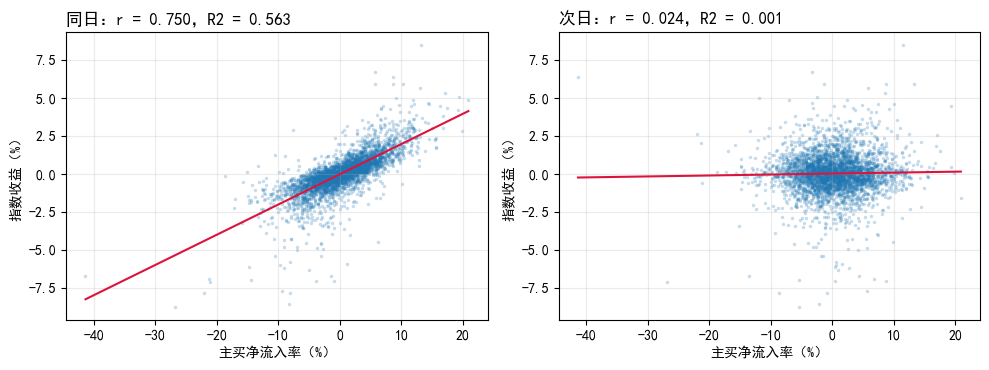

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, ycol, title in [(axes[0], "r", "同日"), (axes[1], "r_next", "次日")]:
    sub = df[["nbi", ycol]].dropna()
    x, y = sub.nbi * 100, sub[ycol] * 100
    ax.scatter(x, y, s=6, alpha=0.25, linewidth=0)
    coef = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, np.polyval(coef, xs), color="crimson", lw=1.5)
    r = np.corrcoef(x, y)[0, 1]
    ax.set_title(f"{title}：r = {r:.3f}，R2 = {r**2:.3f}", loc="left")
    ax.set_xlabel("主买净流入率（%）")
    ax.set_ylabel("指数收益（%）")
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 4. 回归：控制当日收益后是否还有增量信息

Newey-West HAC(5) 标准误，逐步加入当日收益、20 日波动率与对数成交额。

In [8]:
def hac(y, xs, lags=5):
    sub = df[[y] + xs].dropna()
    X = sm.add_constant(sub[xs])
    res = sm.OLS(sub[y], X).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return res


m1 = hac("r", ["nbi"])
m2 = hac("r_next", ["nbi"])
m3 = hac("r_next", ["nbi", "r", "vol20"])

rows = []
for name, res in [("同日 r ~ NBI", m1), ("次日 r_next ~ NBI", m2), ("次日 + 控制变量", m3)]:
    rows.append({"模型": name, "NBI 系数": res.params["nbi"], "t 值": res.tvalues["nbi"],
                 "p 值": res.pvalues["nbi"], "R2": res.rsquared, "n": int(res.nobs)})
pd.DataFrame(rows).round(4)

,模型,NBI 系数,t 值,p 值,R2,n
0,同日 r ~ NBI,0.1994,35.9708,0.0000,0.5629,3590
1,次日 r_next ~ NBI,0.0063,1.1236,0.2612,0.0006,3591
2,次日 + 控制变量,0.0035,0.4257,0.6704,0.0010,3571


## 5. 十分位分组：主买最强/最弱的次日收益

按 `nbi_z` 分 10 组，统计次日平均收益（bp）、胜率与 95% 置信区间。

In [9]:
sub = df[["nbi_z", "r_next"]].dropna().copy()
sub["grp"] = pd.qcut(sub.nbi_z, 10, labels=False)

rows = []
for g, part in sub.groupby("grp"):
    x = part.r_next
    se = x.std(ddof=1) / np.sqrt(len(x))
    rows.append({"组": int(g) + 1, "n": len(x), "次日均值(bp)": x.mean() * 1e4,
                 "95%CI 下界": (x.mean() - 1.96 * se) * 1e4,
                 "95%CI 上界": (x.mean() + 1.96 * se) * 1e4,
                 "胜率": (x > 0).mean()})
dec = pd.DataFrame(rows)

top = sub[sub.grp == 9].r_next
bottom = sub[sub.grp == 0].r_next
print(f"多空价差：{(top.mean() - bottom.mean()) * 1e4:.1f} bp，t = {stats.ttest_ind(top, bottom, equal_var=False).statistic:.2f}")
dec.round(2)

多空价差：15.5 bp，t = 1.39


,组,n,次日均值(bp),95%CI 下界,95%CI 上界,胜率
0,1,348,2.27,-13.86,18.41,0.54
1,2,347,4.47,-9.74,18.69,0.56
2,3,347,-12.65,-26.42,1.12,0.48
3,4,347,7.04,-4.48,18.55,0.54
4,5,347,-3.30,-18.45,11.85,0.50
5,6,347,2.14,-11.18,15.45,0.49
6,7,347,-1.74,-15.98,12.49,0.48
7,8,347,7.43,-6.95,21.80,0.53
8,9,347,-0.19,-13.28,12.91,0.47
9,10,348,17.79,2.95,32.63,0.53


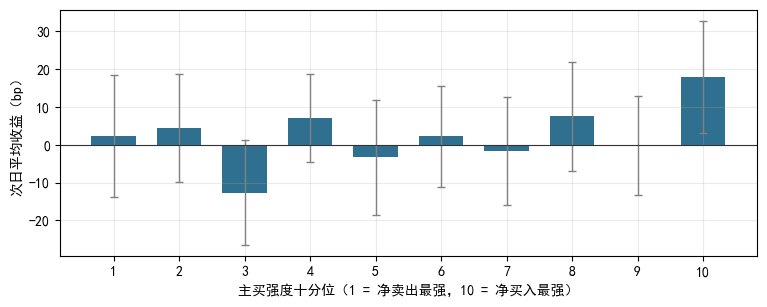

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.2))
means = dec["次日均值(bp)"]
ax.bar(dec["组"], means, color="#2F6F8F", width=0.68)
ax.errorbar(dec["组"], means,
            yerr=[means - dec["95%CI 下界"], dec["95%CI 上界"] - means],
            fmt="none", ecolor="gray", elinewidth=1, capsize=3)
ax.axhline(0, color="#333", lw=0.8)
ax.set_xticks(dec["组"])
ax.set_xlabel("主买强度十分位（1 = 净卖出最强，10 = 净买入最强）")
ax.set_ylabel("次日平均收益（bp）")
ax.grid(alpha=0.25)
plt.show()

## 6. 状态划分：牛市/熊市、低/中/高波动

In [11]:
d = df[["nbi", "r_next", "bull", "vol20"]].dropna().copy()
d["vol_grp"] = pd.qcut(d.vol20, 3, labels=["低波动", "中波动", "高波动"])
d["regime"] = np.where(d.bull, "牛市", "熊市")

rows = []
for name, part in d.groupby("regime", observed=True):
    st = corr_stats(part.nbi, part.r_next, n_boot=200)
    rows.append({"状态": name, "相关系数": st["pearson"], "p 值": st["p"], "n": st["n"]})
for name, part in d.groupby("vol_grp", observed=True):
    st = corr_stats(part.nbi, part.r_next, n_boot=200)
    rows.append({"状态": str(name), "相关系数": st["pearson"], "p 值": st["p"], "n": st["n"]})
pd.DataFrame(rows).round(4)

,状态,相关系数,p 值,n
0,熊市,0.0111,0.6454,1719
1,牛市,0.0421,0.0703,1852
2,低波动,0.0330,0.2556,1191
3,中波动,0.0478,0.0995,1189
4,高波动,0.0145,0.6181,1191


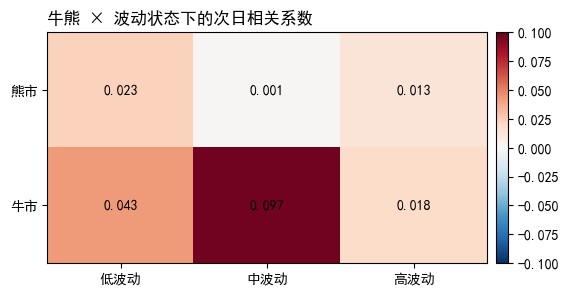

,低波动,中波动,高波动
熊市,0.023,0.001,0.013
牛市,0.043,0.097,0.018


In [12]:
grid = pd.DataFrame(index=["熊市", "牛市"], columns=["低波动", "中波动", "高波动"], dtype=float)
for (reg, vol), part in d.groupby(["regime", "vol_grp"], observed=True):
    grid.loc[reg, str(vol)] = np.corrcoef(part.nbi, part.r_next)[0, 1]

fig, ax = plt.subplots(figsize=(6, 3))
im = ax.imshow(grid.to_numpy(dtype=float), cmap="RdBu_r", vmin=-0.1, vmax=0.1, aspect="auto")
ax.set_xticks(range(3), grid.columns)
ax.set_yticks(range(2), grid.index)
for i in range(2):
    for j in range(3):
        ax.text(j, i, f"{grid.iloc[i, j]:.3f}", ha="center", va="center")
ax.set_title("牛熊 × 波动状态下的次日相关系数", loc="left")
fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
plt.show()
grid.round(3)

## 7. 稳健性：子区间、持有期、替代指标、多重检验

对全部预测性检验做 Benjamini-Hochberg 校正——测试越多，越容易出现"偶然显著"。

In [13]:
# --- 7.1 子区间与替代指标 ---
rows = []
for name, start, end in [("2012-2015", "2012-01-01", "2015-12-31"),
                         ("2016-2019", "2016-01-01", "2019-12-31"),
                         ("2020-2022", "2020-01-01", "2022-12-31"),
                         ("2023-2026", "2023-01-01", "2026-12-31")]:
    part = df[(df.date >= start) & (df.date <= end)]
    st = corr_stats(part.nbi, part.r_next, n_boot=200)
    rows.append({"检验": f"子区间 {name}", "corr": st["pearson"], "p": st["p"], "n": st["n"]})

for col, label in [("r0", "超大单净流入率"), ("divergence", "大单-全单分歧"), ("nbi_s5", "5 日累计主买")]:
    st = corr_stats(df[col], df.r_next, n_boot=200)
    rows.append({"检验": f"指标：{label}", "corr": st["pearson"], "p": st["p"], "n": st["n"]})

for ycol, label in [("r_fwd5", "5 日"), ("r_fwd10", "10 日"), ("r_fwd20", "20 日")]:
    st = corr_stats(df.nbi, df[ycol], n_boot=200)
    rows.append({"检验": f"持有期 {label}", "corr": st["pearson"], "p": st["p"], "n": st["n"]})

robust = pd.DataFrame(rows)
robust.round(4)

,检验,corr,p,n
0,子区间 2012-2015,0.0557,0.0828,970
1,子区间 2016-2019,-0.0281,0.3818,972
2,子区间 2020-2022,-0.0170,0.6473,727
3,子区间 2023-2026,0.0515,0.1182,922
4,指标：超大单净流入率,0.0335,0.0444,3591
5,指标：大单-全单分歧,-0.0036,0.8311,3591
6,指标：5 日累计主买,0.0142,0.3952,3587
7,持有期 5 日,0.0163,0.3283,3587
8,持有期 10 日,0.0066,0.6920,3582
9,持有期 20 日,0.0198,0.2358,3572


In [14]:
# --- 7.2 与报告一致的 15 项预测性检验 + BH 校正 ---
fam, labels = [], []

def add(label, p):
    labels.append(label)
    fam.append(float(p))

add("次日相关 Pearson", nxt["p"])
add("次日相关 Spearman", stats.spearmanr(df.nbi, df.r_next, nan_policy="omit").pvalue)
add("回归 NBI 系数", m2.pvalues["nbi"])
add("回归 NBI 系数(控制)", m3.pvalues["nbi"])
for col, label in [("r0", "超大单净流入率"), ("divergence", "大单-全单分歧"), ("nbi_s5", "5 日累计主买")]:
    add(f"指标：{label}", corr_stats(df[col], df.r_next, n_boot=200)["p"])
for ycol, label in [("r_fwd5", "5 日"), ("r_fwd10", "10 日"), ("r_fwd20", "20 日")]:
    add(f"期限：{label}", corr_stats(df.nbi, df[ycol], n_boot=200)["p"])
for name, part in d.groupby("regime", observed=True):
    add(f"状态：{name}", corr_stats(part.nbi, part.r_next, n_boot=200)["p"])
for name, part in d.groupby("vol_grp", observed=True):
    add(f"状态：{name}", corr_stats(part.nbi, part.r_next, n_boot=200)["p"])

p_raw = np.array(fam)
order = np.argsort(p_raw)
m = len(p_raw)
adj = np.clip(np.minimum.accumulate((p_raw[order] * m / (np.arange(m) + 1))[::-1])[::-1], 0, 1)
p_adj = np.empty(m); p_adj[order] = adj

print(f"检验数 {m} 项：未校正显著 {(p_raw < 0.05).sum()} 项；BH 校正后显著 {(p_adj < 0.05).sum()} 项")
pd.DataFrame({"检验": labels, "原始 p": p_raw, "BH 校正 p": p_adj}).round(4)

检验数 15 项：未校正显著 1 项；BH 校正后显著 0 项


,检验,原始 p,BH 校正 p
0,次日相关 Pearson,0.1561,0.5597
1,次日相关 Spearman,0.8376,0.8376
2,回归 NBI 系数,0.2612,0.5597
3,回归 NBI 系数(控制),0.6704,0.7985
4,指标：超大单净流入率,0.0444,0.4974
5,指标：大单-全单分歧,0.8311,0.8376
6,指标：5 日累计主买,0.3952,0.6587
7,期限：5 日,0.3283,0.6155
8,期限：10 日,0.6920,0.7985
9,期限：20 日,0.2358,0.5597


## 8. 结论

- **同期**：NBI 与当日收益高度同步，说明数据口径可靠，主动买盘确实刻画了当日的买卖压力方向。
- **次日**：相关系数接近 0，回归在控制当日收益后同样不显著；分组、状态、期限与替代指标均未提供稳健反例。
- **多重检验**：未校正时偶有 1 项显著，BH 校正后归零——符合"反复测试撞上偶然显著"的预期。

**解读**：日频主动买盘是成交过程的事后归纳（价格的结果），当日收盘价已把这份买卖压力定价完毕。

**局限与后续**：板块口径可能存在成分回溯偏差；日频聚合抹平日内信息；"主动方"识别为近似而非严格逐笔 Lee-Ready。
后续可用分钟级订单流、个股层面大单/小单分化、ETF 申赎与期指基差做条件分析。